## Homework #2

Katherine Merrill

Phys 434 AB


## Problem 1 

#### A little introductory brain teaser. Which is more probable when rolling 2 six-sided dice: rolling snake eyes (two ones) or rolling sevens (dice sum to seven)? What is the ratio of the probabilities?

The probability of rolling two ones is a product of the individual probabilities, so P(1 and 1)=P(1)P(1)=(1/6)(1/6)=1/36. 

For having the dice sum to seven, there are a number more combinations, being: 
1 and 6;
2 and 5;
3 and 4;
4 and 3;
5 and 2;
6 and 1.
These probabilities add, so the probability of having the dice sum to seven is:
P(1 and 6) + P(2 and 5)+ P(3 and 4)+ P(4 and 3) + P(5 and 2)+ P(6 and 1)
= 6(1/36)=1/6


So the ratio of rolling sevens to rolling snake eyes is (1/6)/(1/36)=6

## Problem 2
#### Following what we did in class show how to use the convolution operator to determine the probability of the sum of 2 six sided dice. Do both analytically (math & counting) and numerically (computer program). Beware the implicit definition of the values (x-axis on histogram).



In class we used $ P_{A+B}(x) = \int_{-\infty}^{\infty} P_A(z) P_B(x - z) \, dz = P_A(x) * P_B(x) $, but since dice have discrete probability values I can rewrite the integral as $P_{A+B}(x)=\sum _{z=1}^{6}P_{A}(z)P_{B}(x-z)$.

So analytically:

For sum x=2, $P_{A+B}(2)=\sum _{z=1}^{6}P_{A}(z)P_{B}(2-z)$, and since the dice can't roll a number less than 1, the the only nonzero term is if z=1, so $ P_A(1)P_B(1) = \frac{1}{6} \times \frac{1}{6} = \mathbf{\frac{1}{36}}$.

For sum x=3:
$P_{A+B}(3)=\sum _{z=1}^{6}P_{A}(z)P_{B}(3-z)$, and the only nonzero term is if z=1 or 2, so: $P_A(1)P_B(1)+P_A(2)P_B(1) = \frac{1}{6} \times \frac{1}{6} +  \frac{1}{6} \times \frac{1}{6} = \mathbf{\frac{1}{36}}+ \mathbf{\frac{1}{36}}=\mathbf{\frac{1}{18}} $.

For sum x=7:

$P_{A+B}(7)=P_{A}(1)P_{B}(6)+P_{A}(2)P_{B}(5)+P_{A}(3)P_{B}(4)+P_{A}(4)P_{B}(3)+P_{A}(5)P_{B}(2)+P_{A}(6)P_{B}(1)$
$= 6 ( \mathbf{\frac{1}{36}})$
$=1/6$

For sum x=12:

$P_{A+B}(12)=P_{A}(6)P_{B}(6)=\mathbf{\frac{1}{36}}$

Numerically:

Sum  Probability
2 0.027777777777777776
3 0.05555555555555555
4 0.08333333333333333
5 0.1111111111111111
6 0.1388888888888889
7 0.16666666666666669
8 0.1388888888888889
9 0.1111111111111111
10 0.08333333333333333
11 0.05555555555555555
12 0.027777777777777776


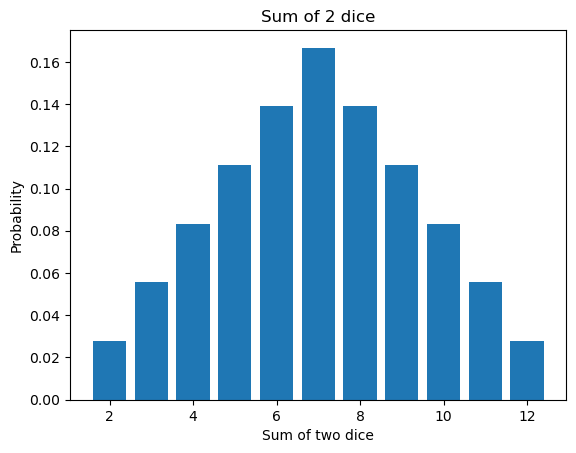

In [16]:
import numpy as np
import matplotlib.pyplot as plt

die_x = np.arange(1, 7)
pdf_die = np.ones(6) / 6

pdf_sum2 = np.convolve(pdf_die, pdf_die)

# for the x-values, smallest sum is 1+1 = 2, largest is 6+6 = 12
sum2_x = np.arange(2, 13)

print("Sum  Probability")
for i in range(len(sum2_x)):
    print(sum2_x[i], pdf_sum2[i])

plt.bar(sum2_x, pdf_sum2)
plt.xlabel('Sum of two dice')
plt.ylabel('Probability')
plt.title('Sum of 2 dice')
plt.show()

## Problem 3: Calculating mean and variance of the distribution


In [12]:
# single die
mean_die = np.sum(die_x * pdf_die)
var_die = np.sum((die_x - mean_die)**2 * pdf_die)

# sum of two dice
mean2 = np.sum(sum2_x * pdf_sum2)
var2 = np.sum((sum2_x - mean2)**2 * pdf_sum2)

print("single die: mean =", mean_die, " variance =", var_die, " (35/12 =", 35/12, ")")
print("sum of 2:   mean =", mean2, " variance =", var2, " (35/6 =", 35/6, ")")
print("std of sum of 2 =", np.sqrt(var2))

single die : mean = 3.5, variance = 2.9166666666666665 (35/12 = 2.9166666666666665)
sum of 2 : mean = 6.999999999999998, variance = 5.833333333333333 (35/6 = 5.833333333333333)
std of sum of 2 = 2.41522945769824


Problem 4

mean = 3.4999999999999982  std = 0.5400617248673215


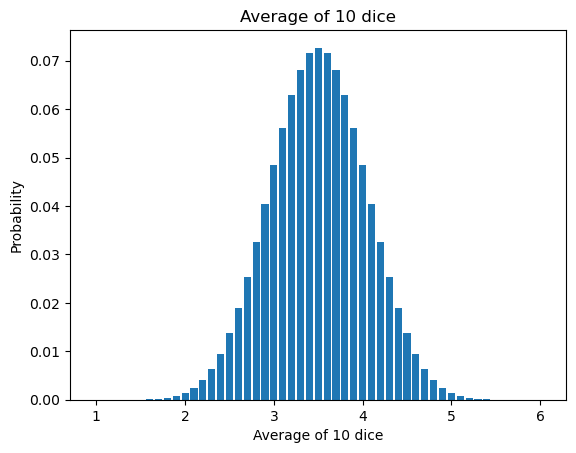

In [15]:
num_dice = 10


pdf_die = np.ones(6) / 6

pdf_sum = pdf_die
for i in range(num_dice - 1):
    pdf_sum = np.convolve(pdf_sum, pdf_die)

sum_x = np.arange(10, 61)

avg_x = sum_x / num_dice

mean = np.sum(avg_x * pdf_sum)
var = np.sum((avg_x - mean)**2 * pdf_sum)
print("mean =", mean, " std =", np.sqrt(var))

plt.bar(avg_x, pdf_sum, width=0.08)
plt.xlabel('Average of 10 dice')
plt.ylabel('Probability')
plt.title('Average of 10 dice')
plt.show()

After plotting it on a semi log y (graphed below), the output is an inverse parabola, which tells me it is a gaussian (or almost gaussian) distribution. 

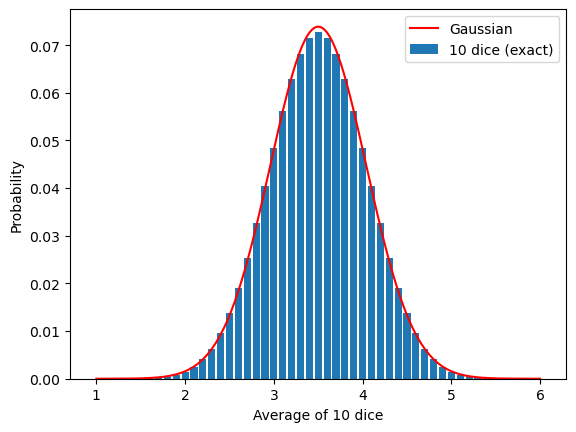

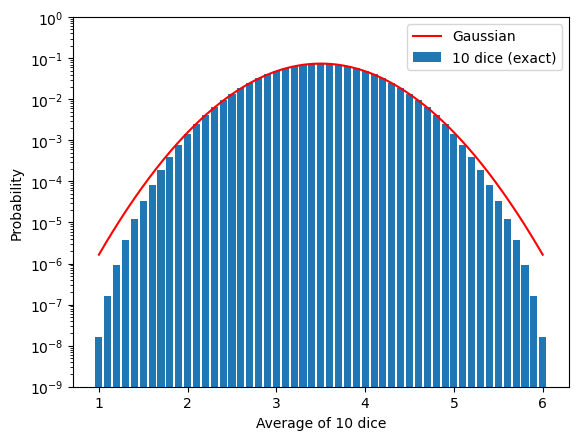

In [19]:
mu = 3.5
sigma = np.sqrt(35/12 / num_dice)

def gauss(x):
    return np.exp(-0.5 * ((x - mu) / sigma)**2) / (sigma * np.sqrt(2 * np.pi))

xx = np.linspace(1, 6, 500)

gauss_curve = gauss(xx) * 0.1

# linear plot
plt.bar(avg_x, pdf_sum, width=0.08, label='10 dice (exact)')
plt.plot(xx, gauss_curve, 'r', label='Gaussian')
plt.xlabel('Average of 10 dice')
plt.ylabel('Probability')
plt.legend()
plt.show()

# log plot
plt.bar(avg_x, pdf_sum, width=0.08, label='10 dice (exact)')
plt.plot(xx, gauss_curve, 'r', label='Gaussian')
plt.yscale('log')
plt.ylim(1e-9, 1)
plt.xlabel('Average of 10 dice')
plt.ylabel('Probability')
plt.legend()
plt.show()


## Problem 5: Show that the sum and average of an initially Gaussian distribution is also a Guassian (can be analytic or numerical). How does the standard deviation of the resulting sum or average Gaussian change? This is a hugely important result. Explore what this means for integrating a signal over time. How does this explain error analysis and error propagation you have done in previous classes (classes that assumed Gaussian errors)?

Analytically:
Let $X_1\sim\mathcal N(\mu_1,\sigma_1^2)$ and $X_2\sim\mathcal N(\mu_2,\sigma_2^2)$ be independent, and let
$Y=X_1+X_2$. The pdf of $Y$ is the convolution of the two pdfs:
$$p(y)=\int_{-\infty}^{\infty} f_1(x_1)\,f_2(y-x_1)\,dx_1
=\frac{1}{2\pi\sigma_1\sigma_2}\int_{-\infty}^{\infty}\exp\!\left\{-\frac12\left[\frac{(x_1-\mu_1)^2}
{\sigma_1^2}+\frac{(y-x_1-\mu_2)^2}{\sigma_2^2}\right]\right\}dx_1
.$$
Define the precisions $w_1=1/\sigma_1^2$ and $w_2=1/\sigma_2^2$. The bracket is quadratic in $x_1$, so 
completing the square:
$$w_1(x_1-\mu_1)^2+w_2(y-x_1-\mu_2)^2=(w_1+w_2)(x_1-\hat x)^2+\frac{w_1w_2}{w_1+w_2}\,(y-\mu_1-\mu_2)^2,
\qquad \hat x=\frac{w_1\mu_1+w_2(y-\mu_2)}{w_1+w_2}.$$
Since
$$\frac{w_1w_2}{w_1+w_2}=\frac{1}{\sigma_1^2+\sigma_2^2},$$
the integrand factors into a part that depends on $x_1$ and a part that depends only on $y$:
$$p(y)=\frac{1}{2\pi\sigma_1\sigma_2}\,\exp\!\left[-\frac{(y-\mu_1-\mu_2)^2}{2(\sigma_1^2+\sigma_2^2)}
\right]\int_{-\infty}^{\infty}\exp\!\left[-\tfrac12
(w_1+w_2)(x_1-\hat x)^2\right]dx_1 .$$
The remaining integral is a Gaussian integral:
$$\int_{-\infty}^{\infty}\exp\!\left[-\tfrac12 (w_1+w_2)(x_1-\hat
x)^2\right]dx_1=\sqrt{\frac{2\pi}{w_1+w_2}}=\sqrt{2\pi}\,\frac{\sigma_1\sigma_2}{\sqrt{\sigma_1^2+
\sigma_2^2}}
.$$
Substituting, the factors $\sigma_1\sigma_2$ cancel and one factor of $\sqrt{2\pi}$ cancels:
$${\,p(y)=\frac{1}{\sqrt{2\pi(\sigma_1^2+\sigma_2^2)}}\exp\!\left[-\frac{\big(y-(\mu_1+\mu_2)\big)^2}
{2(\sigma_1^2+\sigma_2^2)}\right]=\mathcal
N\!\big(y\,\big|\,\mu_1+\mu_2,\ \sigma_1^2+\sigma_2^2\big)\,}$$
So the sum of two independent Gaussians is a Gaussian.

This is an important result because it means that gaussian inputs are still gaussian even if they are summed or averaged, so they can be easily distringuished from other signals or events. For example, if each sample is a constant signal $s$ plus independent
Gaussian noise of standard deviation $\sigma$, then after $N$ samples, the summed signal grows as $Ns$, but the
summed noise grows only as $\sqrt N\,\sigma$. This also means that error analysis is much easier because it means that independent errors on a sum or
difference combine as $\sigma^2=\sigma_1^2+\sigma_2^2$.